In [7]:
# Librerías para manejar rutas y archivos
from pathlib import Path

# Librería para generar los conjuntos de puntos
from sklearn.datasets import make_blobs

# Librerías para ejecutar los programas de C++ y analizar resultados
import subprocess
import pandas as pd
import numpy as np
import os

# Buscar la carpeta principal del proyecto
def find_project_root(start=None):

    # Obtener la carpeta desde donde estamos ejecutando el notebook
    current = Path(start or Path.cwd()).resolve()

    # Buscar la carpeta que contiene .git
    for folder in [current, *current.parents]:
        if (folder / ".git").exists():
            return folder
        
    raise FileNotFoundError("No se encontró la raíz del proyecto")

# Guardar la ruta principal del proyecto
PROJECT_ROOT = find_project_root()

# Carpeta donde se encuentran los datos de entrada
INPUT_DIR = PROJECT_ROOT / "data" / "input"

# Carpetas donde cada programa de C++ guarda sus resultados
OUTPUT_DIR_SERIAL = PROJECT_ROOT / "data" / "output" / "serial"
OUTPUT_DIR_PARALLEL = PROJECT_ROOT / "data" / "output" / "parallel_full"
OUTPUT_DIR_PARALLEL_K = PROJECT_ROOT / "data" / "output" / "parallel_k"

# Carpeta donde se encuentran los programas de C++
SRC_DIR = PROJECT_ROOT / "src"

# Carpeta donde guardaremos los resultados de los experimentos
RESULTADOS_DIR = PROJECT_ROOT / "resultados"

# Crear las carpetas en caso de que no existan
INPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR_SERIAL.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR_PARALLEL.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR_PARALLEL_K.mkdir(parents=True, exist_ok=True)
RESULTADOS_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
# Indicate the number of points
n_points = [20000, 40000, 80000, 120000, 140000, 160000, 180000, 200000]

for n in n_points:
    # randomly generating data points and noise
    points, y_true = make_blobs(n_samples=n,
                                centers=4,
                                cluster_std=0.06,
                                random_state=11,
                                center_box=(0, 1.0))

    # only positive points and with three decimals
    points = np.round(np.abs(points[:, ::-1]), 3)

    input_file = INPUT_DIR / f"{n}_data.csv"

    # storing points into a csv file
    np.savetxt(input_file, points, delimiter=",",  fmt="%.3f")

In [8]:
# Distancia máxima para considerar que dos puntos son vecinos
epsilon = 0.03

# Número mínimo de puntos para considerar que un punto es core
# Se incluye al propio punto
min_puntos = 10

# Obtener el número de procesadores lógicos disponibles
cores_virtuales = os.cpu_count()

# Cantidades de hilos que utilizaremos en los experimentos
# 1 hilo, mitad de los procesadores, todos y el doble
num_hilos = [1, cores_virtuales//2, cores_virtuales, cores_virtuales*2]

# Cantidades de particiones para parallel_k
valores_k = [2, 4, 8, 16, 32, 64]

# Cantidades de puntos que utilizaremos en las pruebas
n_points = [20000, 40000, 80000, 120000, 140000, 160000, 180000, 200000]

# Número de veces que repetiremos cada configuración
num_pruebas = 10

In [4]:
# Ejecutar uno de los programas de C++ y obtener su tiempo
def ejecutar_programa(programa, n, epsilon, min_puntos, num_hilos=None, k=None, num_pruebas=None):

    # Construir el comando que utilizaremos para ejecutar el programa
    # Los tres programas reciben n, epsilon y min_puntos
    comando = [
        str(SRC_DIR / programa),
        str(n),
        str(epsilon),
        str(min_puntos)
    ]

    # El programa serial no recibe número de hilos
    # parallel_full y parallel_k sí lo reciben
    if num_hilos is not None:
        comando.append(str(num_hilos))

    # Solamente parallel_k recibe el número de particiones
    if k is not None:
        comando.append(str(k))

    # parallel_k recibe el número de repeticiones
    if programa == "parallel_k" and num_pruebas is not None:
        comando.append(str(num_pruebas))

    # Ejecutar el programa de C++
    # cwd indica que se ejecutará desde la raíz del proyecto
    # capture_output guarda lo que el programa imprime en la terminal
    resultado = subprocess.run(
        comando,
        cwd=PROJECT_ROOT,
        capture_output=True,
        text=True
    )

    # Verificar si el programa terminó correctamente
    if resultado.returncode != 0:

        # Mostrar los mensajes del programa en caso de error
        print(resultado.stdout)
        print(resultado.stderr)

        raise RuntimeError(
            f"Error al ejecutar {programa} con n={n}, hilos={num_hilos}, k={k}"
        )
    
    # Buscar el tiempo dentro de lo que imprimió el programa
    for linea in resultado.stdout.splitlines():

        # Comprobar si la línea comienza con la etiqueta que buscamos
        if linea.startswith("TIEMPO="):
            # Separar el texto por el signo "=" y convertir el tiempo a float
            return float(linea.split("=")[1])
        
    # Si el programa terminó pero no encontramos el tiempo
    raise RuntimeError(
        f"No se encontró TIEMPO= en la salida de {programa}"
    )

In [7]:
# Lista donde guardaremos los resultados de todas las configuraciones
resultados = []

# Nombres de las columnas del DataFrame y del CSV
columnas = [
    "n_puntos",
    "hilos",
    "k",
    "tiempo_serial",
    "tiempo_parallel_full",
    "tiempo_parallel_k",
    "speedup_full",
    "speedup_k"
]

# Recorrer los diferentes tamaños de datos
for n in n_points:

    # Crear la ruta del CSV correspondiente a esta cantidad de puntos
    CSV_RESULTADOS = RESULTADOS_DIR / f"resultados_{n}.csv"

    # Si el CSV existe y tiene todas las configuraciones, no repetir experimentos
    total_esperado = len(num_hilos) * len(valores_k)

    if CSV_RESULTADOS.exists():

        df_existente = pd.read_csv(CSV_RESULTADOS)

        # Comprobar que se hayan guardado todas las configuraciones
        configuraciones = df_existente[["hilos", "k"]].drop_duplicates()

        if (
            len(configuraciones) == total_esperado
            and df_existente["n_puntos"].eq(n).all()
        ):
            print(f"\nSaltando n = {n}: resultados completos.")
            continue

    # Reiniciar los resultados para esta cantidad de puntos
    resultados = []

    print(f"\nEjecutando n = {n}")

    # -----------------------------------
    # Versión serial
    # -----------------------------------

    # Guardar los tiempos de cada repetición serial
    tiempo_serial = []

    # Ejecutar la versión serial num_pruebas veces
    for prueba in range(num_pruebas):

        tiempo = ejecutar_programa(
            "serial",
            n,
            epsilon,
            min_puntos
        )

        # Guardar el tiempo de esta repetición
        tiempo_serial.append(tiempo)

    # Calcular el tiempo promedio de la versión serial
    tiempo_serial_promedio = sum(tiempo_serial) / num_pruebas

    # Recorrer las diferentes cantidades de hilos
    for hilos in num_hilos:

        # -----------------------------------
        # Primera versión paralela
        # -----------------------------------

        # Guardar los tiempos de cada repetición
        tiempo_parallel = []

        # Ejecutar parallel_full num_pruebas veces
        for prueba in range(num_pruebas):

            tiempo = ejecutar_programa(
                "parallel_full",
                n,
                epsilon,
                min_puntos,
                hilos
            )

            tiempo_parallel.append(tiempo)

        # Calcular el tiempo promedio de parallel_full
        tiempo_parallel_full_promedio = (
            sum(tiempo_parallel) / num_pruebas
        )

        # Calcular el speedup respecto a la versión serial
        speedup_full = (
            tiempo_serial_promedio / tiempo_parallel_full_promedio
        )

        # -----------------------------------
        # Segunda versión paralela
        # -----------------------------------

        # Probar las diferentes cantidades de particiones
        for k in valores_k:

            # Ejecutar parallel_k con todas las repeticiones dentro de C++
            # Las particiones se construyen una sola vez por ejecución
            tiempo_parallel_k_promedio = ejecutar_programa(
                "parallel_k",
                n,
                epsilon,
                min_puntos,
                hilos,
                k,
                num_pruebas
            )

            # Calcular el speedup respecto a la versión serial
            speedup_k = (
                tiempo_serial_promedio / tiempo_parallel_k_promedio
            )

            # Guardar los resultados de la configuración actual
            resultados.append({
                "n_puntos": n,
                "hilos": hilos,
                "k": k,
                "tiempo_serial": tiempo_serial_promedio,
                "tiempo_parallel_full": tiempo_parallel_full_promedio,
                "tiempo_parallel_k": tiempo_parallel_k_promedio,
                "speedup_full": speedup_full,
                "speedup_k": speedup_k
            })

            # Crear el DataFrame con los resultados obtenidos hasta ahora
            df_resultados = pd.DataFrame(
                resultados,
                columns=columnas
            )

            # Guardar los resultados en el CSV
            # Se actualiza después de cada configuración
            df_resultados.to_csv(
                CSV_RESULTADOS,
                index=False
            )

# Mostrar mensaje cuando terminen todos los experimentos
print("\nExperimentos finalizados")

# Mostrar la ubicación del CSV
print(f"Resultados guardados en: {RESULTADOS_DIR}")


Saltando n = 20000: resultados completos.

Saltando n = 40000: resultados completos.

Ejecutando n = 80000

Ejecutando n = 120000

Ejecutando n = 140000

Ejecutando n = 160000

Ejecutando n = 180000

Ejecutando n = 200000

Experimentos finalizados
Resultados guardados en: /home/valentina/Documentos/ITAM/Septimo Semestre/computo_paralelo/dbscan-omp/resultados


In [18]:
# Leer los archivos de resultados de cada cantidad de puntos
archivos = [
    RESULTADOS_DIR / f"resultados_{n}.csv"
    for n in n_points
]

# Unir los resultados en un solo DataFrame
df_resultados = pd.concat(
    [pd.read_csv(archivo) for archivo in archivos],
    ignore_index=True
)

# Ordenar los resultados por puntos, hilos y particiones
df_resultados = df_resultados.sort_values(
    by=["n_puntos", "hilos", "k"]
).reset_index(drop=True)

# Guardar todos los resultados en un único CSV
CSV_FINAL = RESULTADOS_DIR / "resultados_completos.csv"

df_resultados.to_csv(CSV_FINAL, index=False)

# Mostrar los resultados
print(f"Total de configuraciones: {len(df_resultados)}")
print(f"Archivo guardado en: {CSV_FINAL}")

display(df_resultados)

Total de configuraciones: 192
Archivo guardado en: /home/valentina/Documentos/ITAM/Septimo Semestre/computo_paralelo/dbscan-omp/resultados/resultados_completos.csv


,n_puntos,hilos,k,tiempo_serial,tiempo_parallel_full,tiempo_parallel_k,speedup_full,speedup_k
0,20000,1,2,0.346611,0.319203,0.321900,1.085865,1.076767
1,20000,1,4,0.346611,0.319203,0.244403,1.085865,1.418196
2,20000,1,8,0.346611,0.319203,0.230658,1.085865,1.502707
3,20000,1,16,0.346611,0.319203,0.209311,1.085865,1.655964
4,20000,1,32,0.346611,0.319203,0.193173,1.085865,1.794306
...,...,...,...,...,...,...,...,...
187,200000,24,4,49.085170,14.183350,26.696800,3.460760,1.838616
188,200000,24,8,49.085170,14.183350,16.762000,3.460760,2.928360
189,200000,24,16,49.085170,14.183350,14.983600,3.460760,3.275926
190,200000,24,32,49.085170,14.183350,9.884960,3.460760,4.965642


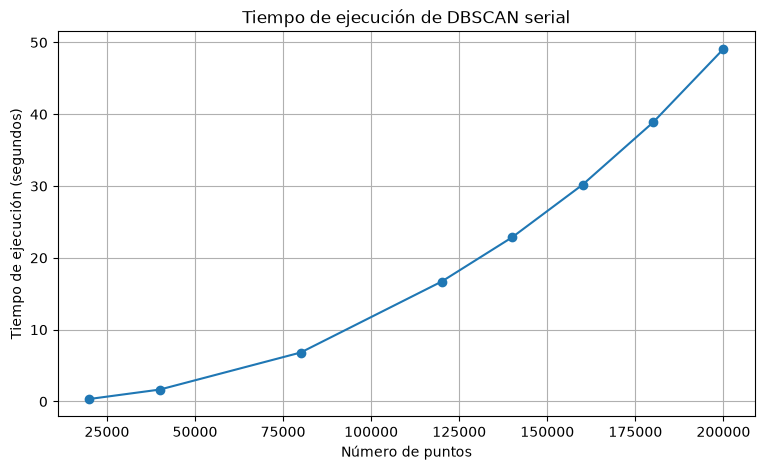

In [4]:
import matplotlib.pyplot as plt

# Obtener un tiempo serial por cada cantidad de puntos
df_serial = (
    df_resultados[["n_puntos", "tiempo_serial"]]
    .drop_duplicates(subset=["n_puntos"])
    .sort_values("n_puntos")
)

plt.figure(figsize=(9, 5))

plt.plot(
    df_serial["n_puntos"],
    df_serial["tiempo_serial"],
    marker="o"
)

plt.xlabel("Número de puntos")
plt.ylabel("Tiempo de ejecución (segundos)")
plt.title("Tiempo de ejecución de DBSCAN serial")

plt.grid(True)
plt.show()

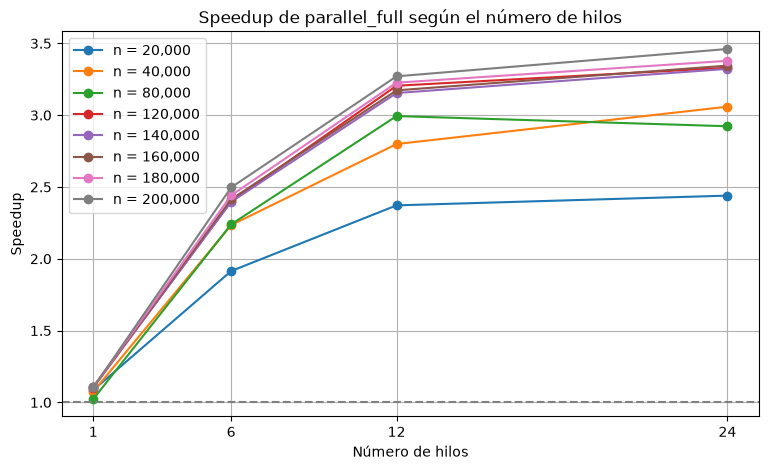

In [5]:
# Obtener un resultado por combinación de puntos e hilos
df_full = (
    df_resultados[
        ["n_puntos", "hilos", "speedup_full"]
    ]
    .drop_duplicates(subset=["n_puntos", "hilos"])
)

plt.figure(figsize=(9, 5))

# Dibujar una línea por cantidad de puntos
for n in sorted(df_full["n_puntos"].unique()):

    datos = df_full[
        df_full["n_puntos"] == n
    ].sort_values("hilos")

    plt.plot(
        datos["hilos"],
        datos["speedup_full"],
        marker="o",
        label=f"n = {n:,}"
    )

plt.xlabel("Número de hilos")
plt.ylabel("Speedup")
plt.title("Speedup de parallel_full según el número de hilos")

plt.xticks(sorted(df_full["hilos"].unique()))
plt.axhline(y=1, linestyle="--", color="gray")

plt.legend()
plt.grid(True)
plt.show()

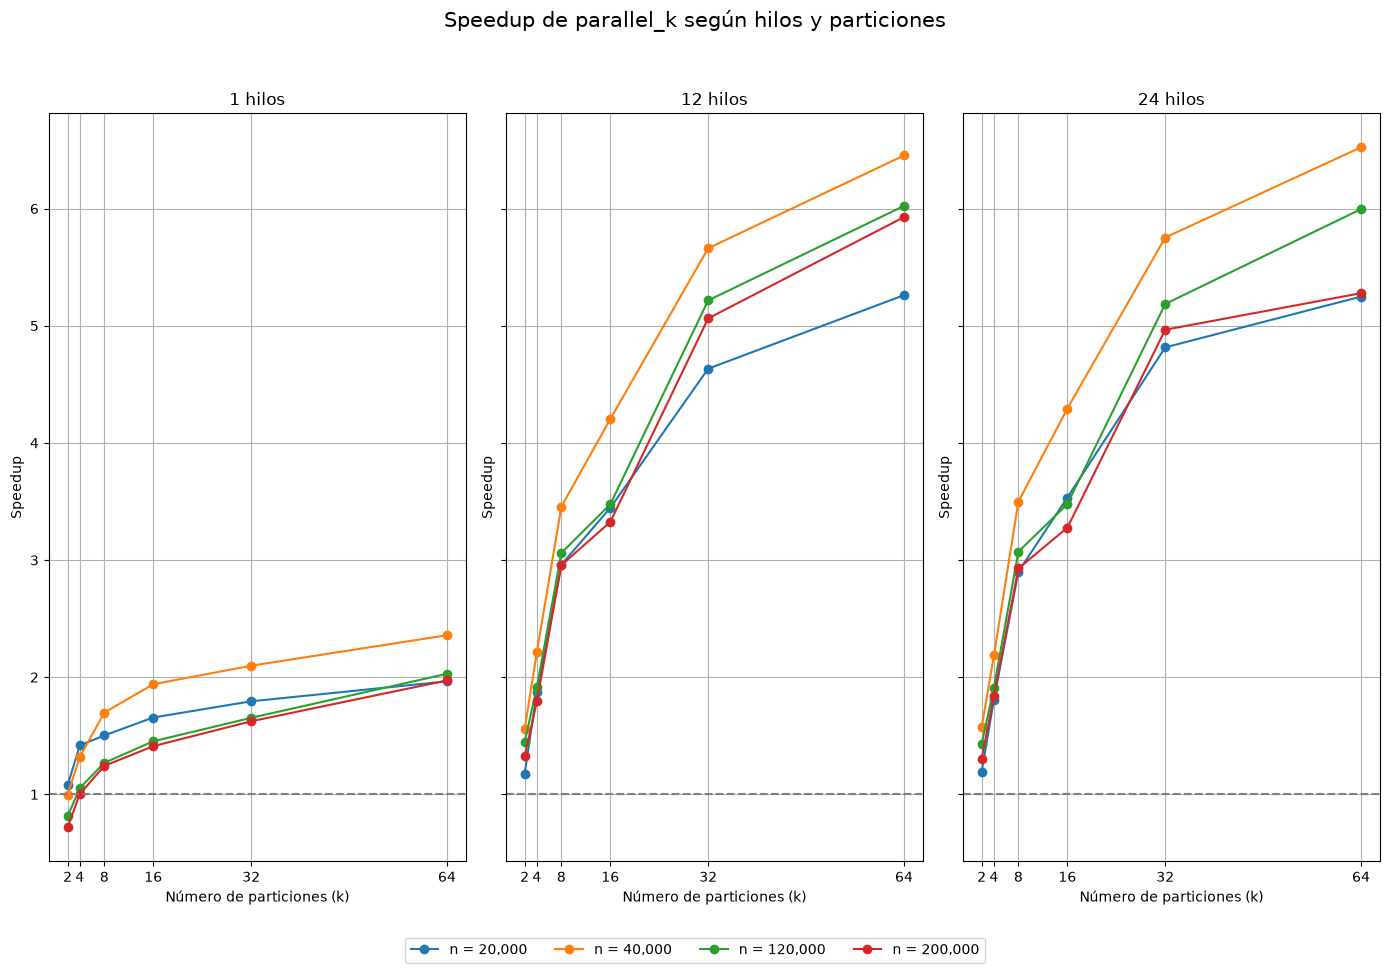

In [15]:
import matplotlib.pyplot as plt

# Cantidades de hilos que queremos analizar
hilos_graficas = [1, 12, 24]

# Cantidades de puntos que mostraremos
puntos_seleccionados = [20000, 40000, 120000, 200000]

# Crear una figura con cuatro gráficas (2 filas y 2 columnas)
fig, axes = plt.subplots(1, 3, figsize=(14, 10), sharey=True)

# Convertir la matriz de ejes en una lista para recorrerla fácilmente
axes = axes.flatten()

# Generar una gráfica por cada cantidad de hilos
for i, hilos in enumerate(hilos_graficas):

    # Seleccionar la gráfica correspondiente
    ax = axes[i]

    # Filtrar los resultados para esta cantidad de hilos
    df_k = df_resultados[
        (df_resultados["hilos"] == hilos) &
        (df_resultados["n_puntos"].isin(puntos_seleccionados))
    ]

    # Dibujar una línea por cada cantidad de puntos
    for n in puntos_seleccionados:

        datos = df_k[
            df_k["n_puntos"] == n
        ].sort_values("k")

        ax.plot(
            datos["k"],
            datos["speedup_k"],
            marker="o",
            label=f"n = {n:,}"
        )

    # Configurar cada gráfica
    ax.set_title(f"{hilos} hilos")
    ax.set_xlabel("Número de particiones (k)")
    ax.set_ylabel("Speedup")

    ax.set_xticks(valores_k)
    ax.axhline(y=1, linestyle="--", color="gray")
    ax.grid(True)

# Agregar un título general
fig.suptitle(
    "Speedup de parallel_k según hilos y particiones",
    fontsize=15
)

# Colocar una sola leyenda para las cuatro gráficas
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=4,
    bbox_to_anchor=(0.5, 0.02)
)

# Ajustar los espacios entre las gráficas
plt.tight_layout(rect=[0, 0.07, 1, 0.95])

plt.show()

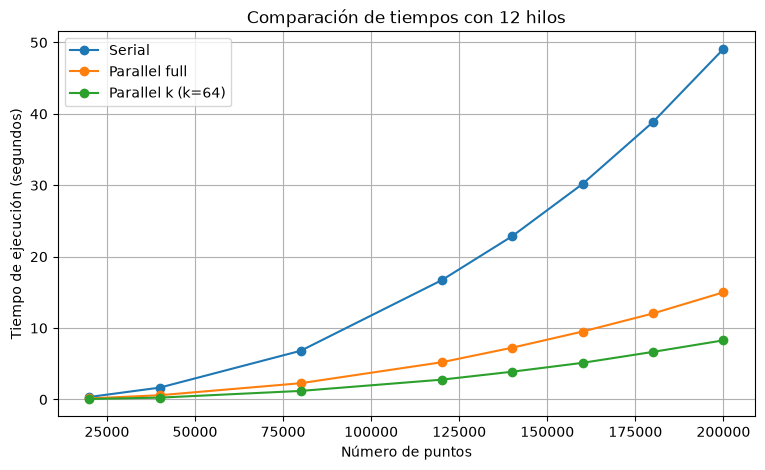

In [16]:
# Seleccionar las configuraciones que queremos comparar
hilos_fijos = 12
k_fijo = 64

df_comparacion = (
    df_resultados[
        (df_resultados["hilos"] == hilos_fijos) &
        (df_resultados["k"] == k_fijo)
    ]
    .sort_values("n_puntos")
)

plt.figure(figsize=(9, 5))

# Versión serial
plt.plot(
    df_comparacion["n_puntos"],
    df_comparacion["tiempo_serial"],
    marker="o",
    label="Serial"
)

# Primera versión paralela
plt.plot(
    df_comparacion["n_puntos"],
    df_comparacion["tiempo_parallel_full"],
    marker="o",
    label="Parallel full"
)

# Segunda versión paralela
plt.plot(
    df_comparacion["n_puntos"],
    df_comparacion["tiempo_parallel_k"],
    marker="o",
    label=f"Parallel k (k={k_fijo})"
)

plt.xlabel("Número de puntos")
plt.ylabel("Tiempo de ejecución (segundos)")
plt.title(f"Comparación de tiempos con {hilos_fijos} hilos")

plt.legend()
plt.grid(True)
plt.show()

In [17]:
# Cantidades de puntos que queremos verificar
n_points = [20000, 40000, 80000, 120000, 140000, 160000, 180000, 200000]

# Guardar los resultados de las comparaciones
resultados_validacion = []

for n in n_points:

    # Rutas de los CSV generados por cada implementación
    archivo_serial = OUTPUT_DIR_SERIAL / f"{n}_results.csv"
    archivo_full = OUTPUT_DIR_PARALLEL / f"{n}_results_parallel_full.csv"
    archivo_k = OUTPUT_DIR_PARALLEL_K / f"{n}_results_parallel_k.csv"

    # Comprobar que existan los tres archivos
    if not all(archivo.exists() for archivo in [archivo_serial, archivo_full, archivo_k]):
        print(f"n = {n}: faltan archivos CSV")
        continue

    # Leer las coordenadas y clasificaciones
    serial = pd.read_csv(
        archivo_serial,
        header=None,
        names=["x", "y", "asignacion"]
    )

    full = pd.read_csv(
        archivo_full,
        header=None,
        names=["x", "y", "asignacion"]
    )

    parallel_k = pd.read_csv(
        archivo_k,
        header=None,
        names=["x", "y", "asignacion"]
    )

    # Comprobar que tengan la misma cantidad de puntos
    misma_cantidad = (
        len(serial) == len(full) == len(parallel_k) == n
    )

    # Comprobar que sean los mismos puntos y estén en el mismo orden
    mismas_coordenadas = False

    if misma_cantidad:
        mismas_coordenadas = (
            np.allclose(
                serial[["x", "y"]],
                full[["x", "y"]],
                rtol=0,
                atol=1e-6
            )
            and
            np.allclose(
                serial[["x", "y"]],
                parallel_k[["x", "y"]],
                rtol=0,
                atol=1e-6
            )
        )

    # Si los puntos no coinciden, no podemos comparar por posición
    if not mismas_coordenadas:
        print(f"n = {n}: ERROR, los puntos o su orden son diferentes")
        continue

    # Identificar qué puntos fueron clasificados como ruido
    ruido_serial = serial["asignacion"] == -1
    ruido_full = full["asignacion"] == -1
    ruido_k = parallel_k["asignacion"] == -1

    # Contar diferencias respecto a la versión serial
    diferencias_full = (ruido_serial != ruido_full).sum()
    diferencias_k = (ruido_serial != ruido_k).sum()

    # Comprobar si las tres implementaciones coinciden
    coinciden = diferencias_full == 0 and diferencias_k == 0

    # Guardar los resultados
    resultados_validacion.append({
        "n_puntos": n,
        "ruido_serial": ruido_serial.sum(),
        "ruido_full": ruido_full.sum(),
        "ruido_k": ruido_k.sum(),
        "diferencias_full": diferencias_full,
        "diferencias_k": diferencias_k,
        "coinciden": coinciden
    })

    # Mostrar el resultado de cada tamaño
    if coinciden:
        print(f"n = {n}: CORRECTO, las tres implementaciones coinciden")
    else:
        print(f"n = {n}: ERROR, existen diferencias")


# Crear una tabla con los resultados de validación
df_validacion = pd.DataFrame(resultados_validacion)

display(df_validacion)

# Comprobar que se validaron todos los conjuntos de datos
if len(df_validacion) == len(n_points) and df_validacion["coinciden"].all():
    print("\nVALIDACIÓN EXITOSA: todos los archivos coinciden en la detección de ruido.")
else:
    print("\nVALIDACIÓN INCOMPLETA: faltan archivos o existen diferencias.")

n = 20000: CORRECTO, las tres implementaciones coinciden
n = 40000: CORRECTO, las tres implementaciones coinciden
n = 80000: CORRECTO, las tres implementaciones coinciden
n = 120000: CORRECTO, las tres implementaciones coinciden
n = 140000: CORRECTO, las tres implementaciones coinciden
n = 160000: CORRECTO, las tres implementaciones coinciden
n = 180000: CORRECTO, las tres implementaciones coinciden
n = 200000: CORRECTO, las tres implementaciones coinciden


,n_puntos,ruido_serial,ruido_full,ruido_k,diferencias_full,diferencias_k,coinciden
0,20000,45,45,45,0,0,True
1,40000,33,33,33,0,0,True
2,80000,34,34,34,0,0,True
3,120000,38,38,38,0,0,True
4,140000,35,35,35,0,0,True
5,160000,28,28,28,0,0,True
6,180000,27,27,27,0,0,True
7,200000,21,21,21,0,0,True



VALIDACIÓN EXITOSA: todos los archivos coinciden en la detección de ruido.
